<H1> Financial Market Dynamics: Statistical Modelling, Econometric Analysis and Time-Series Forecasting of the S&P 500 (2016–2026) </H1>

<B1> **Research question:** To what extent can financial market indicators explain fluctuations in S&P 500 returns, and how effectively can historical market data be used to forecast future market movements? </B1>

<B1> **Phase 2: Statistical and Econometric Analysis**  </B1>

<B1> **Name:** Syed Zaid </B1> 

<B1> **Dataset Source:** Federal Reserve Bank of St. Louis – Federal Reserve Economic Data (FRED) </B1> 

<B1> **Domain:** Financial Markets, Stock Market Volatility and Macroeconomic Indicators </B1> 

<B1> **Study Period:** October 2016 – October 2026. </B1>

# Phase 2: Statistical and Econometric Analysis

<H2> 1. Import all the Libraries </H2>

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualisation settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
C:\Users\reshma begum\Desktop\Projects\sp500-financial-market-analysis\Notebooks


## 2. Dataset Loading and Verification

This phase investigates the statistical relationships between selected financial market indicators and S&P 500 returns.

The analysis uses the cleaned dataset produced during Phase 1, covering the period from November 2016 to October 2026.

The dependent variable is S&P 500 daily returns, while the explanatory variables include changes in market volatility, Treasury yields, Brent crude oil returns and the Federal Funds Rate.

The dataset will first be loaded and verified before proceeding with descriptive statistics, exploratory data analysis and econometric modelling.


In [2]:
df = pd.read_csv(r"C:\Users\reshma begum\Desktop\Projects\sp500-financial-market-analysis/Data/Processed/Financial_dataset_cleaned.csv")

print("\nFirst Five Observations:")
df.head()


First Five Observations:


,Date,SP500_Close,VIX,Treasury_10Y,Brent_Oil,Fed_Rate,SP500_Return,VIX_Change,Treasury_10Y_Change,Brent_Oil_Return,Fed_Rate_Change
0,2016-11-04,2085.1800,22.5100,1.7900,43.0600,0.4100,-0.1666,0.4300,-0.0300,-1.7792,0.0000
1,2016-11-07,2131.5200,18.7100,1.8300,42.8300,0.4100,2.2224,-3.8000,0.0400,-0.5341,0.0000
2,2016-11-08,2139.5600,18.7400,1.8800,43.4700,0.4100,0.3772,0.0300,0.0500,1.4943,0.0000
3,2016-11-09,2163.2600,14.3800,2.0700,43.8800,0.4100,1.1077,-4.3600,0.1900,0.9432,0.0000
4,2016-11-10,2167.4800,14.7400,2.1500,43.6700,0.4100,0.1951,0.3600,0.0800,-0.4786,0.0000


In [3]:
df['Date'] = pd.to_datetime(df['Date'])
df['Date'].head()

0   2016-11-04
1   2016-11-07
2   2016-11-08
3   2016-11-09
4   2016-11-10
Name: Date, dtype: datetime64[ns]

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (2320, 11)

Column Names:
['Date', 'SP500_Close', 'VIX', 'Treasury_10Y', 'Brent_Oil', 'Fed_Rate', 'SP500_Return', 'VIX_Change', 'Treasury_10Y_Change', 'Brent_Oil_Return', 'Fed_Rate_Change']

Data Types:
Date                   datetime64[ns]
SP500_Close                   float64
VIX                           float64
Treasury_10Y                  float64
Brent_Oil                     float64
Fed_Rate                      float64
SP500_Return                  float64
VIX_Change                    float64
Treasury_10Y_Change           float64
Brent_Oil_Return              float64
Fed_Rate_Change               float64
dtype: object

Missing Values:
Date                   0
SP500_Close            0
VIX                    0
Treasury_10Y           0
Brent_Oil              0
Fed_Rate               0
SP500_Return           0
VIX_Change             0
Treasury_10Y_Change    0
Brent_Oil_Return       0
Fed_Rate_Change        0
dtype: int64


## 3. Descriptive Statistics

Descriptive statistical analysis is conducted to examine the distribution and characteristics of the variables selected for econometric modelling.

The analysis focuses on five variables: S&P 500 daily returns, changes in the VIX, changes in the 10-year US Treasury yield, Brent crude oil returns and changes in the Federal Funds Rate.

Measures of central tendency, dispersion and distribution shape are examined to understand the behaviour of each variable and identify potential characteristics that may influence subsequent statistical modelling.

The analysis includes the mean, median, standard deviation, variance, minimum, maximum, skewness and kurtosis.


### A. Generate descriptive statistics

In [5]:
model_variables = [
    'SP500_Return',
    'VIX_Change',
    'Treasury_10Y_Change',
    'Brent_Oil_Return',
    'Fed_Rate_Change'
]

descriptive_stats = df[model_variables].describe().T

display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max
SP500_Return,2320.0000,0.0660,1.1511,-11.9841,-0.3635,0.0914,0.6051,9.5154
VIX_Change,2320.0000,-0.0323,1.9963,-18.7100,-0.7800,-0.1400,0.5100,24.8600
Treasury_10Y_Change,2320.0000,0.0010,0.0534,-0.3000,-0.0300,0.0000,0.0300,0.2900
Brent_Oil_Return,2320.0000,0.1172,3.2203,-47.4654,-1.1571,0.1344,1.3980,50.9868
Fed_Rate_Change,2320.0000,0.0013,0.0494,-0.8500,0.0000,0.0000,0.0000,0.7500


### B. Calculate skewness and kurtosis

In [6]:
distribution_stats = pd.DataFrame({
    'Skewness': df[model_variables].skew(),
    'Kurtosis': df[model_variables].kurt()
})

display(distribution_stats)

,Skewness,Kurtosis
SP500_Return,-0.4257,16.3204
VIX_Change,2.2043,33.6537
Treasury_10Y_Change,-0.0692,2.2161
Brent_Oil_Return,0.6991,59.3618
Fed_Rate_Change,3.9305,151.4000


### C. Calculate the interquartile range

In [7]:
iqr_stats = pd.DataFrame({
    'Q1': df[model_variables].quantile(0.25),
    'Q3': df[model_variables].quantile(0.75),
    'IQR': (
        df[model_variables].quantile(0.75) -
        df[model_variables].quantile(0.25)
    )
})

display(iqr_stats)

,Q1,Q3,IQR
SP500_Return,-0.3635,0.6051,0.9686
VIX_Change,-0.7800,0.5100,1.2900
Treasury_10Y_Change,-0.0300,0.0300,0.0600
Brent_Oil_Return,-1.1571,1.3980,2.5551
Fed_Rate_Change,0.0000,0.0000,0.0000


### Interpretation of Descriptive Statistics

The descriptive statistical analysis reveals substantial differences in the distribution and variability of the selected financial indicators.

S&P 500 daily returns exhibit a positive mean of 0.0660% and a standard deviation of 1.1511 percentage points. The negative skewness of -0.4257 indicates a moderately asymmetric distribution towards negative returns, while excess kurtosis of 16.3204 suggests considerably heavier tails than a normal distribution.

VIX changes demonstrate positive skewness of 2.2043 and excess kurtosis of 33.6537, indicating that substantial increases in market volatility occur relatively infrequently but contribute to extreme observations.

Treasury yield changes exhibit relatively low dispersion and near-zero skewness. However, their positive excess kurtosis of 2.2161 indicates heavier tails than those of a normal distribution.

Brent crude oil returns display considerable variability, with a standard deviation of 3.2203 percentage points. Their positive skewness of 0.6991 and exceptionally high excess kurtosis of 59.3618 indicate an asymmetric distribution with substantial extreme observations.

Federal Funds Rate changes exhibit the most pronounced distributional characteristics, with skewness of 3.9305 and excess kurtosis of 151.4000. The interquartile range is zero, indicating a substantial concentration of observations around zero, consistent with the relatively infrequent adjustment of monetary policy rates.

Overall, the descriptive statistics indicate that several variables exhibit substantial departures from normality, particularly in terms of skewness and tail behaviour. These characteristics will be considered during subsequent exploratory analysis and regression diagnostics.


## 4. Exploratory Data Analysis (EDA)

### A. Distribution Analysis

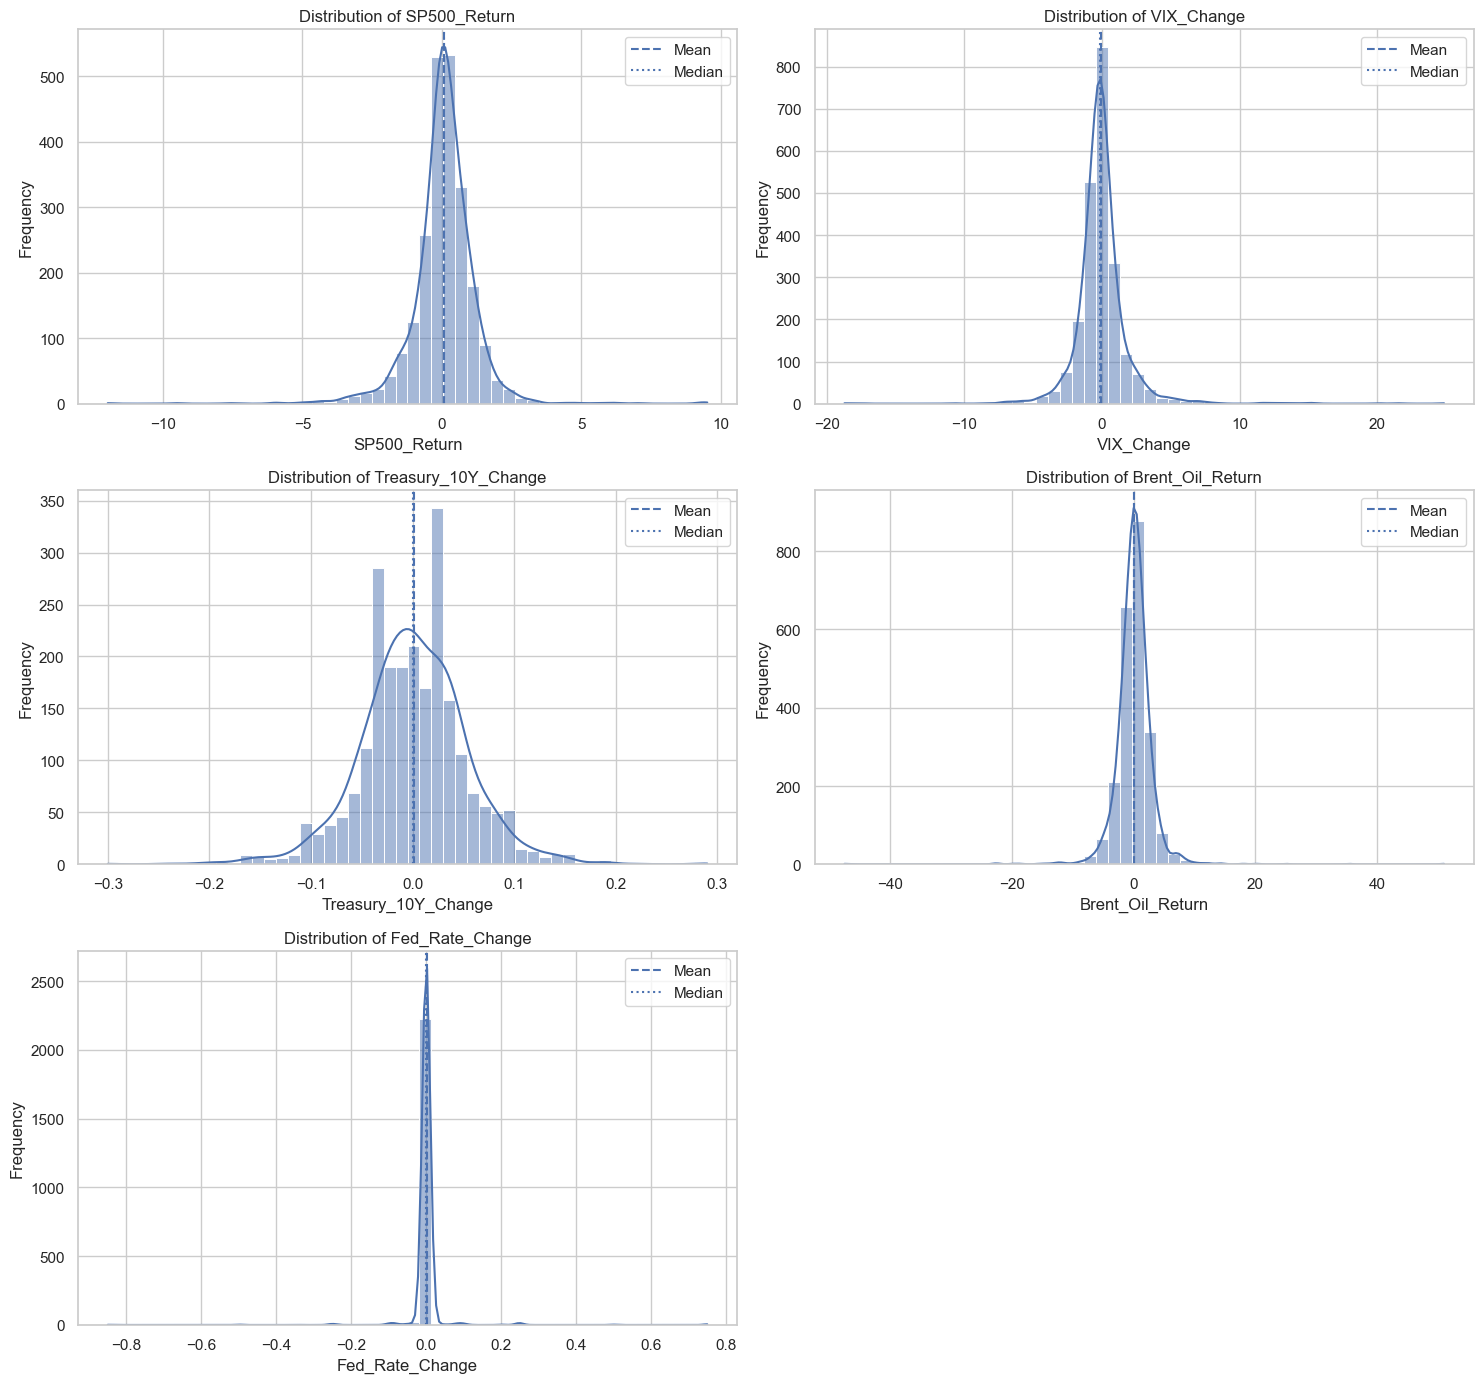

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for ax, column in zip(axes.flatten(), model_variables):

    sns.histplot(
        data=df,
        x=column,
        bins=50,
        kde=True,
        ax=ax
    )

    ax.axvline(
        df[column].mean(),
        linestyle='--',
        label='Mean'
    )

    ax.axvline(
        df[column].median(),
        linestyle=':',
        label='Median'
    )

    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Frequency')
    ax.legend()

# Remove unused subplot
axes.flatten()[-1].remove()

plt.tight_layout()
plt.show()

### Interpretation of Distribution Plots

The histograms reveal distinct distributional characteristics across the five financial variables.

S&P 500 daily returns are concentrated around zero, with a broadly bell-shaped central distribution and moderately negative skewness. However, the presence of observations in both tails indicates that extreme market movements occur within the sample.

VIX changes exhibit a pronounced right-skewed distribution. Although most daily changes are relatively small, occasional substantial increases in market volatility produce an extended right tail.

Changes in the 10-year Treasury yield are relatively concentrated around zero and exhibit an approximately symmetric distribution. The visible concentration around particular values reflects the discrete nature of observed daily yield movements.

Brent crude oil returns demonstrate substantial dispersion and pronounced tail behaviour. Most observations are concentrated around zero, while relatively few extreme movements extend considerably in both directions.

Federal Funds Rate changes display a particularly concentrated distribution, with a substantial proportion of observations at zero. Nonzero changes occur relatively infrequently, producing a distribution with pronounced tails and substantial positive skewness.

Overall, the visual analysis supports the descriptive statistical findings. Several variables exhibit asymmetric distributions and substantial tail behaviour, suggesting that extreme observations and departures from normality should be considered during subsequent econometric modelling.


### B. Boxplot Analysis

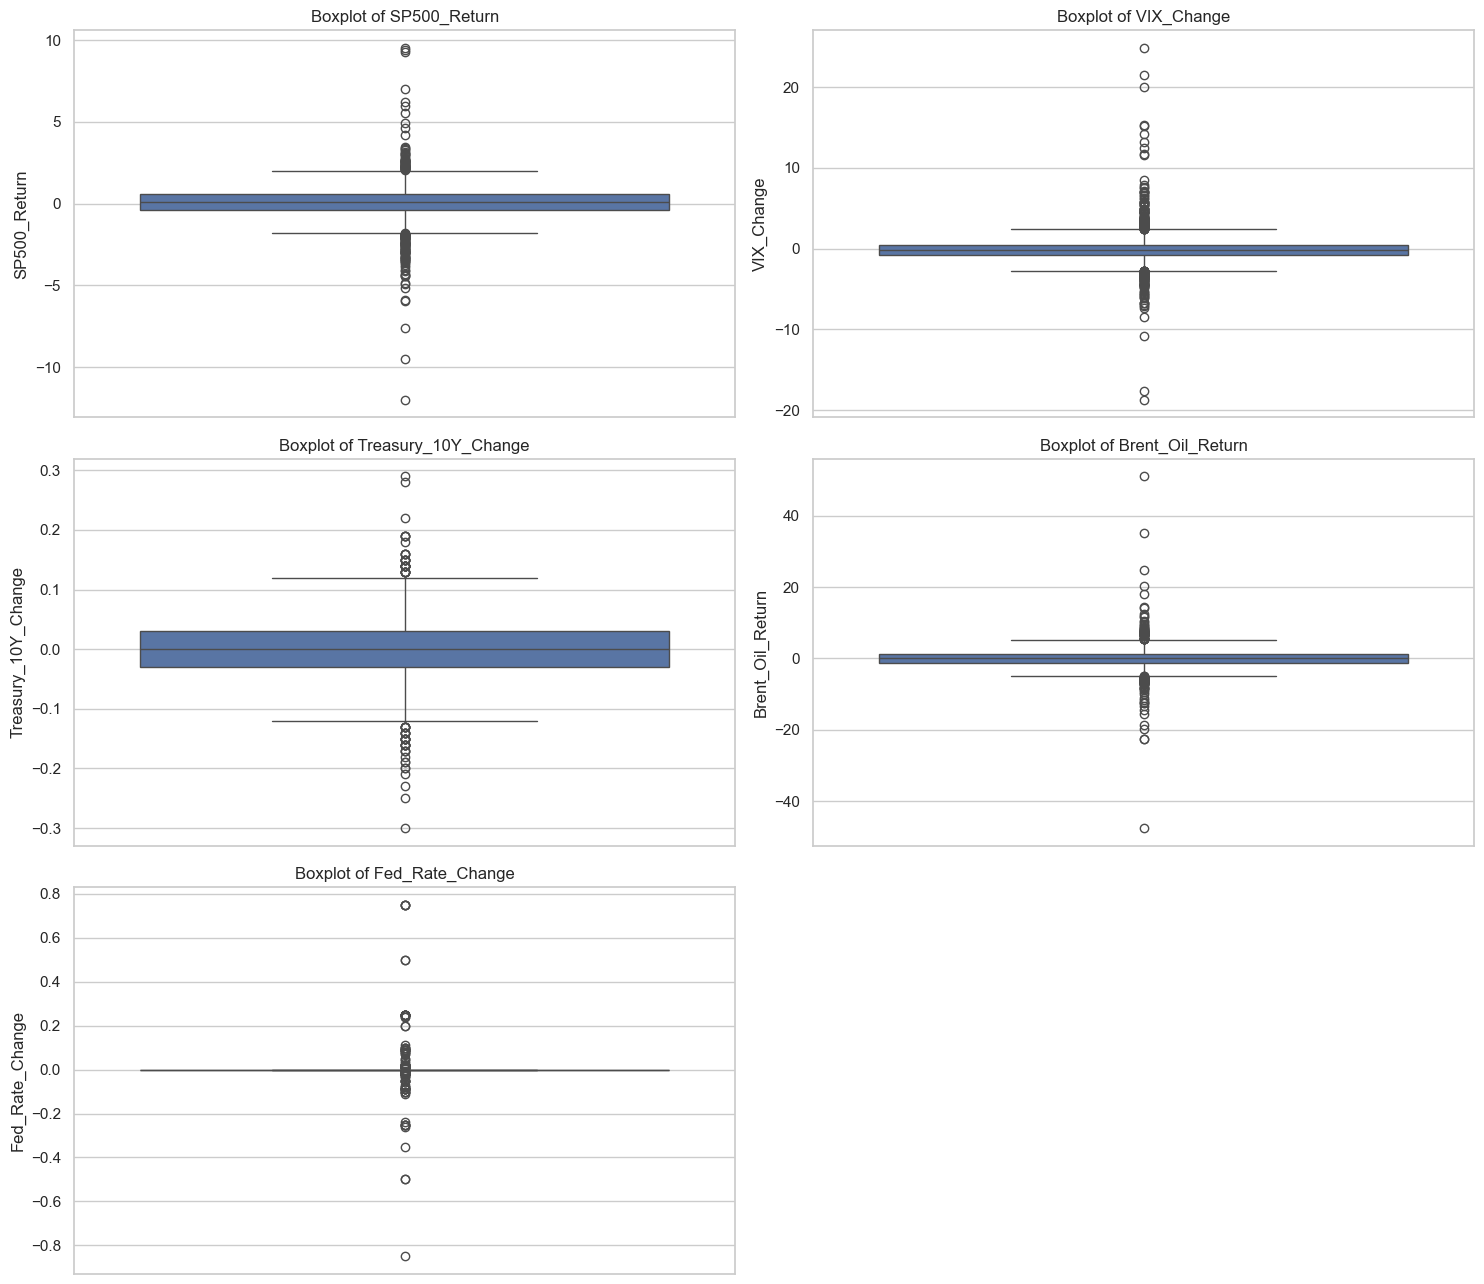

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(15, 13))

for ax, column in zip(axes.flatten(), model_variables):

    sns.boxplot(
        data=df,
        y=column,
        ax=ax
    )

    ax.set_title(f'Boxplot of {column}')
    ax.set_ylabel(column)

axes.flatten()[-1].remove()

plt.tight_layout()
plt.show()

### Interpretation of Boxplots

The boxplot analysis provides further insight into the dispersion and potential extreme observations within the selected financial variables.

S&P 500 returns exhibit a relatively concentrated interquartile range, with numerous observations beyond the upper and lower whiskers. The presence of extreme observations on both sides indicates substantial tail behaviour, with particularly notable negative movements.

VIX changes demonstrate considerable dispersion outside the interquartile range. The positive tail extends further than the negative tail, indicating the presence of occasional substantial increases in market volatility.

Changes in the 10-year Treasury yield exhibit a comparatively narrow central distribution, with most observations concentrated around zero. Nevertheless, potential outliers are present on both sides, indicating occasional substantial changes in Treasury yields.

Brent crude oil returns display numerous observations beyond the whiskers, including particularly extreme positive and negative movements. This is consistent with the high excess kurtosis identified during descriptive statistical analysis.

Federal Funds Rate changes exhibit a particularly concentrated distribution, with the interquartile range effectively collapsing to zero. The nonzero observations are consequently identified as potential outliers, reflecting the relatively infrequent adjustment of monetary policy rates.

Overall, the boxplots confirm the presence of potential extreme observations across all five variables. These observations are not automatically treated as erroneous data points. Given the financial nature of the dataset, they may represent genuine market movements and will be retained for subsequent analysis. Their potential influence on regression estimates will be investigated through regression diagnostics.


### C. Time-Series Visualisation

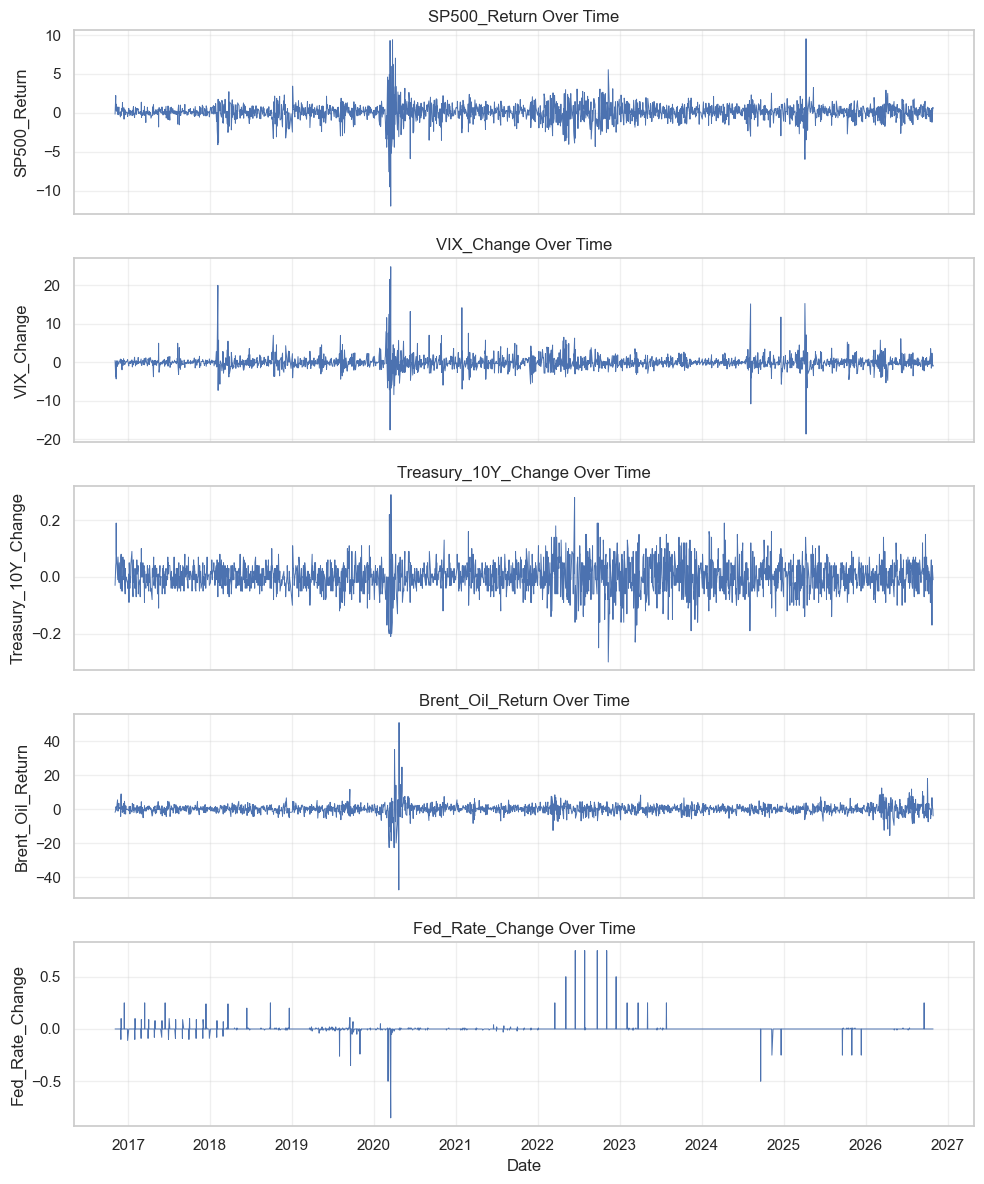

In [10]:
fig, axes = plt.subplots(5, 1, figsize=(10, 12), sharex=True)

for ax, column in zip(axes, model_variables):

    ax.plot(
        df['Date'],
        df[column],
        linewidth=0.7
    )

    ax.set_title(f'{column} Over Time')
    ax.set_ylabel(column)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')

plt.tight_layout()
plt.show()

### Interpretation of Time-Series Visualisations

The time-series visualisations reveal substantial variation in the behaviour of the selected financial indicators throughout the study period.

S&P 500 daily returns fluctuate around zero, with identifiable periods of elevated volatility, particularly around 2020. Additional clusters of large daily movements are visible during 2022–2023 and 2025. This suggests the presence of volatility clustering, a characteristic commonly observed in financial return series.

Changes in the VIX exhibit similar periods of elevated activity, with particularly pronounced movements around 2020 and 2025. The visual correspondence between VIX changes and S&P 500 return volatility suggests a potential relationship between market volatility and equity market movements, which will be investigated through subsequent correlation and regression analysis.

Changes in the 10-year Treasury yield exhibit relatively limited daily variation during the earlier part of the sample, followed by periods of greater fluctuation, particularly around 2020 and 2022–2023. This indicates that the variability of Treasury yields changes over time.

Brent crude oil returns demonstrate considerable fluctuations, with an especially pronounced concentration of extreme movements around 2020. Additional periods of elevated variability are visible towards the end of the sample. These observations are consistent with the substantial dispersion and excess kurtosis identified during descriptive statistical analysis.

Federal Funds Rate changes exhibit a distinct temporal pattern. Unlike the other financial indicators, the series contains extended periods of zero daily changes interrupted by discrete adjustments. More concentrated periods of monetary policy adjustments are visible around 2022–2023.

Overall, the time-series visualisations indicate that financial market variables exhibit different temporal characteristics. Several series demonstrate periods of elevated volatility, while Federal Funds Rate changes reflect relatively infrequent policy adjustments. These observations provide motivation for investigating the relationships between the variables and assessing their suitability for econometric modelling.


### D. Comparative Analysis

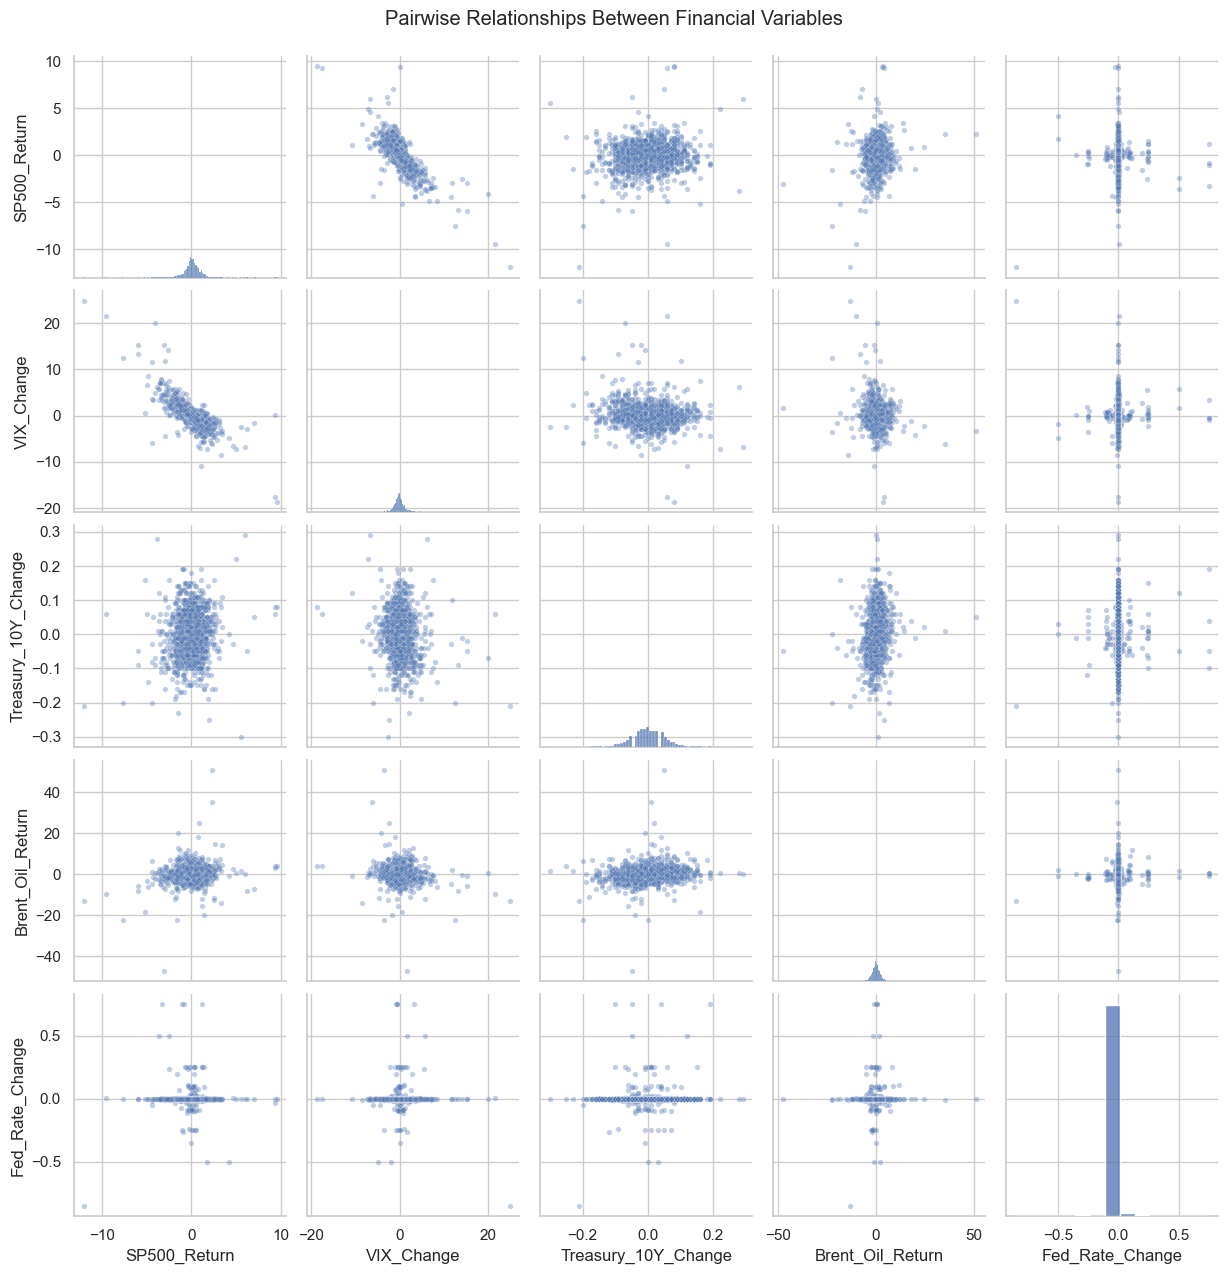

In [11]:
sns.pairplot(
    df[model_variables],
    diag_kind='hist',
    plot_kws={
        'alpha': 0.35,
        's': 15
    },
    height=2.5
)

plt.suptitle(
    'Pairwise Relationships Between Financial Variables',
    y=1.02
)

plt.show()

### Interpretation of Pairwise Relationships

The pairplot provides an initial visual assessment of the relationships between the five variables selected for econometric modelling.

The most noticeable relationship is between S&P 500 returns and changes in the VIX. The scatterplot indicates a negative linear association, whereby increases in the VIX tend to coincide with negative S&P 500 returns, while decreases in the VIX are generally associated with more positive returns. This observation provides motivation for investigating the relationship through simple linear regression.

The relationship between S&P 500 returns and changes in the 10-year Treasury yield appears comparatively weak, with observations widely dispersed around the centre of the distribution.

Similarly, Brent crude oil returns do not exhibit an immediately apparent strong linear relationship with S&P 500 returns. Although some variation is visible, the scatterplot does not indicate a clear linear pattern.

The relationship between S&P 500 returns and Federal Funds Rate changes is difficult to assess visually because a substantial proportion of observations are concentrated at zero. The relatively infrequent occurrence of nonzero changes also limits the visible pattern.

The pairwise relationships among the explanatory variables do not reveal particularly obvious strong linear associations, although this requires further investigation through correlation analysis and multicollinearity diagnostics.

Overall, the pairplot suggests that changes in the VIX may have the strongest contemporaneous linear association with S&P 500 returns among the selected explanatory variables. These preliminary observations will be examined quantitatively in the subsequent covariance and correlation analysis.


## 5. Covariance and Correlation Analysis

### A. covariance

In [12]:
covariance_matrix = df[model_variables].cov()
print("covariance matrix:")
display(covariance_matrix)

covariance matrix:


,SP500_Return,VIX_Change,Treasury_10Y_Change,Brent_Oil_Return,Fed_Rate_Change
SP500_Return,1.3250,-1.8075,0.0071,0.6533,0.0007
VIX_Change,-1.8075,3.9854,-0.0131,-0.9781,-0.0045
Treasury_10Y_Change,0.0071,-0.0131,0.0029,0.0284,0.0001
Brent_Oil_Return,0.6533,-0.9781,0.0284,10.3705,0.0061
Fed_Rate_Change,0.0007,-0.0045,0.0001,0.0061,0.0024


### B. correlation

In [13]:
correlation_matrix = df[model_variables].corr(method='pearson')
print("correlation matrix:")
display(correlation_matrix)

correlation matrix:


,SP500_Return,VIX_Change,Treasury_10Y_Change,Brent_Oil_Return,Fed_Rate_Change
SP500_Return,1.0000,-0.7866,0.1148,0.1762,0.0115
VIX_Change,-0.7866,1.0000,-0.1226,-0.1521,-0.0456
Treasury_10Y_Change,0.1148,-0.1226,1.0000,0.1654,0.0491
Brent_Oil_Return,0.1762,-0.1521,0.1654,1.0000,0.0380
Fed_Rate_Change,0.0115,-0.0456,0.0491,0.0380,1.0000


### C. heatmap

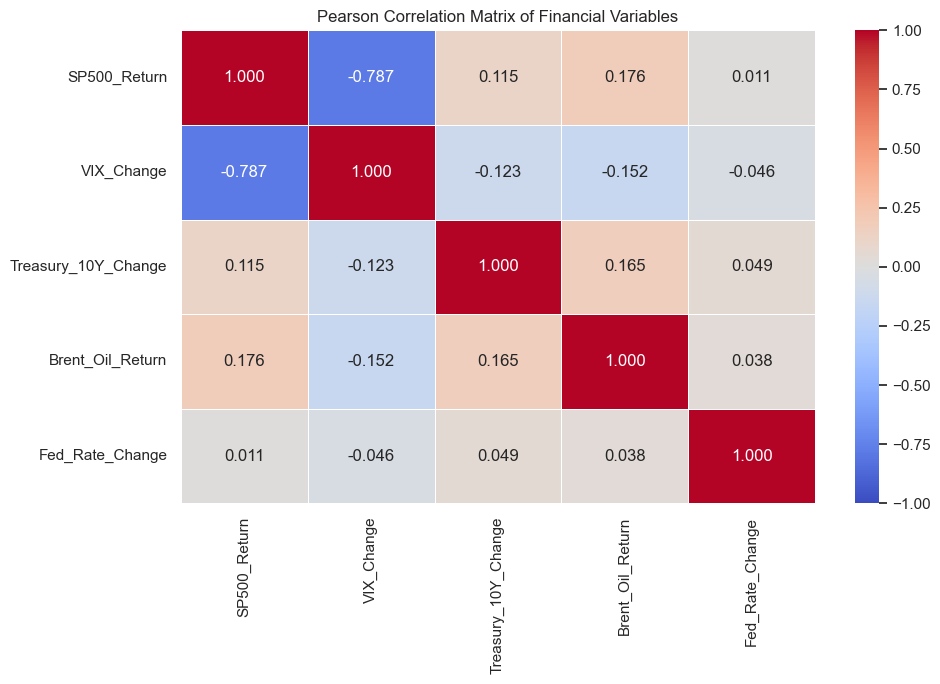

In [14]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Pearson Correlation Matrix of Financial Variables')
plt.tight_layout()
plt.show()

In [15]:
sp500_correlations = correlation_matrix['SP500_Return'].drop(
    'SP500_Return'
).sort_values()
print("Strongest relationships with SP 500 returns:")
display(sp500_correlations)

Strongest relationships with SP 500 returns:


VIX_Change            -0.7866
Fed_Rate_Change        0.0115
Treasury_10Y_Change    0.1148
Brent_Oil_Return       0.1762
Name: SP500_Return, dtype: float64

### Interpretation of Covariance and Correlation Analysis

The covariance and Pearson correlation matrices provide quantitative evidence of the relationships between the selected financial market indicators.

The strongest relationship identified is between S&P 500 returns and changes in the VIX, with a Pearson correlation coefficient of -0.7866. This indicates a strong negative contemporaneous linear association, suggesting that increases in market volatility tend to coincide with negative equity returns.

Changes in the 10-year US Treasury yield exhibit a weak positive correlation with S&P 500 returns (r = 0.1148). Similarly, Brent crude oil returns demonstrate a weak positive correlation (r = 0.1762). These results suggest that the contemporaneous linear relationships between these variables and S&P 500 returns are comparatively limited.

Federal Funds Rate changes exhibit a correlation coefficient of 0.0115 with S&P 500 returns, indicating a negligible linear association within the sample. This result should be interpreted in the context of the variable's highly concentrated distribution and relatively infrequent daily adjustments.

The correlations among the explanatory variables are also relatively weak. The largest absolute pairwise correlation is approximately 0.1654, between Treasury yield changes and Brent crude oil returns. Although this suggests limited pairwise linear dependence, formal multicollinearity diagnostics will be conducted during the regression analysis.

Overall, the correlation analysis identifies VIX changes as the variable with the strongest contemporaneous linear association with S&P 500 returns. This provides a statistical basis for proceeding with simple linear regression, followed by multiple linear regression incorporating all four explanatory variables.

These correlations describe contemporaneous associations and do not establish causation or predictive ability.


## 6. Simple Linear Regression

In [16]:
# Import Statsmodels
import statsmodels.api as sm

# Define dependent and independent variables
X = df[['VIX_Change']]
y = df['SP500_Return']

# Add intercept
X = sm.add_constant(X)

# Fit the regression model
slr_model = sm.OLS(y, X).fit()

print(slr_model.summary())

                            OLS Regression Results                            
Dep. Variable:           SP500_Return   R-squared:                       0.619
Model:                            OLS   Adj. R-squared:                  0.619
Method:                 Least Squares   F-statistic:                     3761.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:10:04   Log-Likelihood:                -2499.4
No. Observations:                2320   AIC:                             5003.
Df Residuals:                    2318   BIC:                             5014.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0513      0.015      3.478      0.0

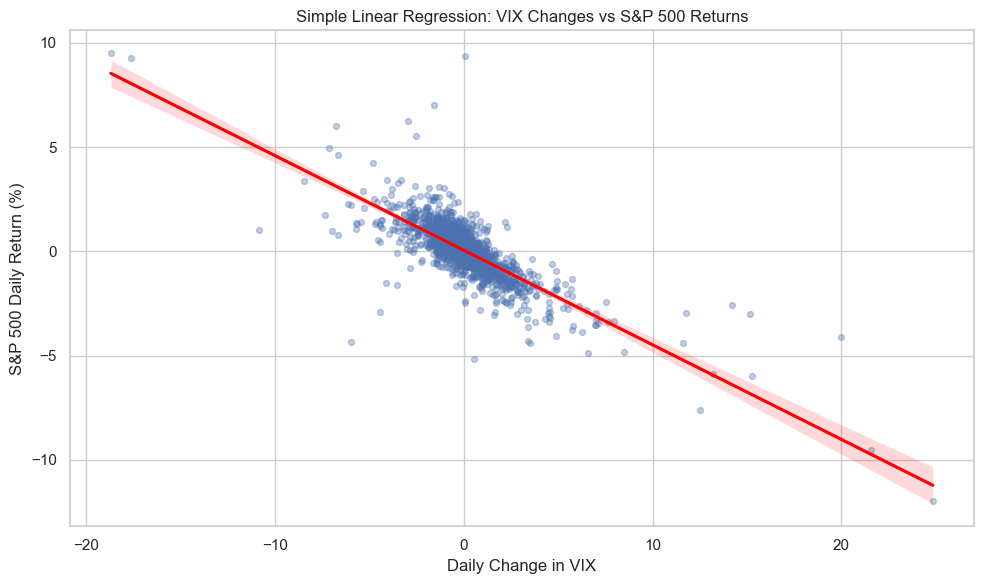

In [17]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='VIX_Change',
    y='SP500_Return',
    scatter_kws={'alpha': 0.35, 's': 18},
    line_kws={'color': 'red'}
)

plt.title('Simple Linear Regression: VIX Changes vs S&P 500 Returns')
plt.xlabel('Daily Change in VIX')
plt.ylabel('S&P 500 Daily Return (%)')

plt.tight_layout()
plt.show()

### Interpretation of Simple Linear Regression Results

A simple ordinary least squares (OLS) regression was estimated to investigate the relationship between changes in the CBOE Volatility Index (VIX) and S&P 500 daily returns.

The estimated regression coefficient for VIX changes is -0.4535, indicating that a one-point increase in the VIX is associated with an estimated 0.4535 percentage-point decrease in S&P 500 daily returns, on average.

The model produces an R-squared value of 0.619, suggesting that approximately 61.9% of the sample variation in S&P 500 daily returns is explained by its linear relationship with VIX changes.

The estimated coefficient is statistically significant, with a t-statistic of -61.329 and a p-value below 0.001. Its 95% confidence interval ranges from -0.468 to -0.439, excluding zero.

The overall regression model is also statistically significant, with an F-statistic of 3761 and a corresponding p-value below 0.001. Therefore, the null hypothesis of no linear relationship between VIX changes and S&P 500 returns is rejected.

Initial diagnostic statistics indicate that the residuals depart from normality, as evidenced by the Jarque-Bera statistic of 65,167.013. The Durbin-Watson statistic of 2.063, however, suggests little evidence of first-order residual autocorrelation.

Overall, the regression identifies a strong and statistically significant negative contemporaneous association between changes in market volatility and S&P 500 daily returns. Nevertheless, the model's residual distribution and other regression assumptions require further investigation before drawing conclusions about the reliability of conventional statistical inference.


## 7. Multiple Linear Regression

Multiple linear regression is employed to investigate the combined relationship between selected financial market indicators and S&P 500 daily returns.

The model incorporates four explanatory variables: daily changes in the VIX, daily changes in the 10-year US Treasury yield, daily Brent crude oil returns and daily changes in the Federal Funds Rate.

The objective is to examine the individual contribution of each explanatory variable while controlling for the effects of the other variables.

The multiple regression model will also be compared with the simple linear regression model to determine whether incorporating additional financial indicators improves the explanatory performance of the model.


### A. Define the independent and dependent variables

In [18]:
# Independent variables
X_mlr = df[
    [
        'VIX_Change',
        'Treasury_10Y_Change',
        'Brent_Oil_Return',
        'Fed_Rate_Change'
    ]
]

# Dependent variable
y_mlr = df['SP500_Return']

# Add intercept
X_mlr = sm.add_constant(X_mlr)

### B. Fit the multiple linear regression model

In [19]:
mlr_model = sm.OLS(y_mlr, X_mlr).fit()

print(mlr_model.summary())

                            OLS Regression Results                            
Dep. Variable:           SP500_Return   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     955.6
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:10:05   Log-Likelihood:                -2486.9
No. Observations:                2320   AIC:                             4984.
Df Residuals:                    2315   BIC:                             5013.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.0497    

### C. Visualise actual vs predicted values

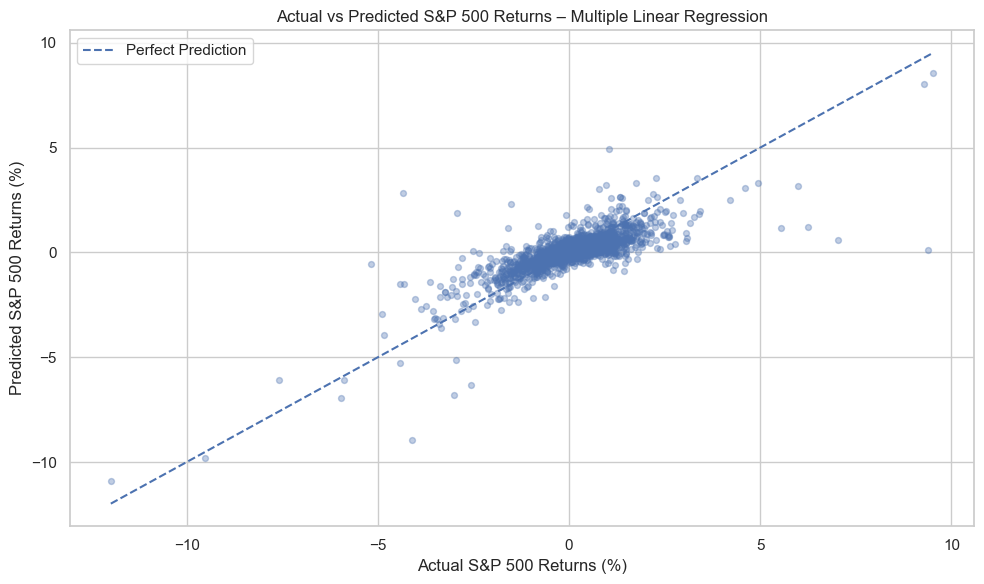

In [20]:
# Generate predictions
mlr_predictions = mlr_model.predict(X_mlr)

# Actual vs predicted plot
plt.figure(figsize=(10, 6))

plt.scatter(
    y_mlr,
    mlr_predictions,
    alpha=0.35,
    s=18
)

# Reference line
min_val = min(y_mlr.min(), mlr_predictions.min())
max_val = max(y_mlr.max(), mlr_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--',
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted S&P 500 Returns – Multiple Linear Regression')
plt.xlabel('Actual S&P 500 Returns (%)')
plt.ylabel('Predicted S&P 500 Returns (%)')
plt.legend()

plt.tight_layout()
plt.show()

### D. Compare SLR and MLR

In [21]:
model_comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'R-squared': [
        slr_model.rsquared,
        mlr_model.rsquared
    ],
    'Adjusted R-squared': [
        slr_model.rsquared_adj,
        mlr_model.rsquared_adj
    ],
    'AIC': [
        slr_model.aic,
        mlr_model.aic
    ],
    'BIC': [
        slr_model.bic,
        mlr_model.bic
    ]
})

display(model_comparison)

,Model,R-squared,Adjusted R-squared,AIC,BIC
0,Simple Linear Regression,0.6187,0.6185,5002.8226,5014.3212
1,Multiple Linear Regression,0.6228,0.6221,4983.8121,5012.5587


### Interpretation of Multiple Linear Regression Results

A multiple ordinary least squares (OLS) regression was estimated to investigate the combined relationship between S&P 500 daily returns and four financial market indicators: changes in the VIX, changes in the 10-year US Treasury yield, Brent crude oil returns and changes in the Federal Funds Rate.

The estimated coefficient for VIX changes is -0.4484 and is statistically significant at the 1% level. Holding the other explanatory variables constant, a one-point increase in the VIX is associated with an estimated 0.4484 percentage-point decrease in S&P 500 daily returns. The coefficient remains close to the estimate obtained through simple linear regression, suggesting that the inclusion of additional predictors does not materially alter the estimated VIX relationship.

Changes in the 10-year Treasury yield produce a positive coefficient of 0.2438 but are not statistically significant (p = 0.385). Consequently, there is insufficient evidence of an independent linear association between Treasury yield changes and S&P 500 returns within this model.

Brent crude oil returns have a positive and statistically significant coefficient of 0.0204 (p < 0.001). This indicates a relatively small positive association with S&P 500 returns, conditional on the other explanatory variables.

Federal Funds Rate changes produce a negative coefficient of -0.6229, which is statistically significant at the 5% level (p = 0.037). However, this finding requires cautious interpretation because the variable is heavily concentrated around zero and nonzero policy adjustments occur relatively infrequently.

The model produces an R-squared of 0.6228 and an adjusted R-squared of 0.6221, compared with 0.6187 and 0.6185 respectively for the simple linear regression model. The increase in explanatory power is therefore relatively modest. The AIC and BIC also decrease, indicating an improvement in model fit after accounting for model complexity.

The actual versus predicted plot indicates that the model captures the general concentration of daily returns around zero but struggles to reproduce the magnitude of some extreme positive and negative observations.

Overall, the multiple regression model is statistically significant and provides a modest improvement over the simple regression model. However, VIX changes remain the dominant explanatory variable, while the additional financial indicators provide comparatively limited incremental explanatory power.

These results represent contemporaneous statistical associations rather than causal relationships or evidence of out-of-sample forecasting performance.


## 8. Regression Diagnostics

Regression diagnostics are conducted to evaluate whether the estimated OLS models satisfy the assumptions required for reliable statistical inference.

Although the regression models produce statistically significant results, their reliability depends on the behaviour of the residuals and the relationships between explanatory variables.

The diagnostic analysis examines linearity, heteroscedasticity, residual independence, normality, multicollinearity and influential observations.

The results will help determine whether conventional OLS standard errors are appropriate or whether alternative estimation and inference methods are required.


### A. Calculate MLR residuals and fitted values

In [22]:
# Extract fitted values and residuals
mlr_fitted = mlr_model.fittedvalues
mlr_residuals = mlr_model.resid

print("Mean of residuals:", mlr_residuals.mean())
print("Standard deviation of residuals:", mlr_residuals.std())

Mean of residuals: 8.269247355828753e-17
Standard deviation of residuals: 0.7069603416067293


### B. Plot residuals against fitted values

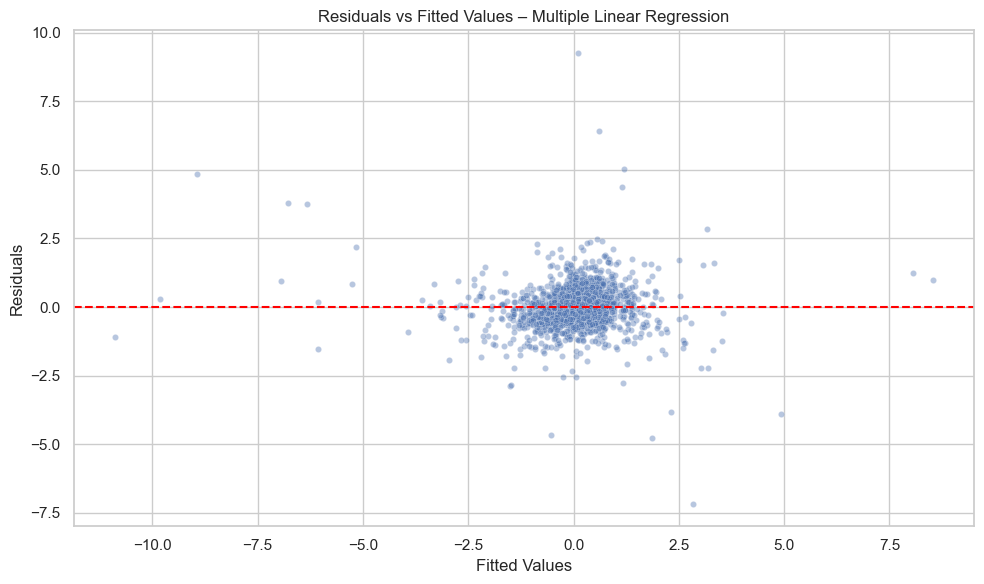

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=mlr_fitted,
    y=mlr_residuals,
    alpha=0.4,
    s=20
)

plt.axhline(
    y=0,
    linestyle='--',
    color='red'
)

plt.title('Residuals vs Fitted Values – Multiple Linear Regression')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')

plt.tight_layout()
plt.show()

### Interpretation of Residual Analysis

The residual analysis provides an initial assessment of the adequacy of the multiple linear regression model.

The mean residual is approximately zero (8.27 × 10⁻¹⁷), which is consistent with the mathematical properties of OLS estimation when an intercept is included. The residual standard deviation is approximately 0.707 percentage points.

The residuals versus fitted values plot shows that most observations are concentrated around the zero reference line. No immediately apparent systematic curved pattern is visible, suggesting that the model captures the broad linear relationship between the explanatory variables and S&P 500 returns.

However, several relatively large residuals are visible, and the dispersion of residuals may vary across the fitted-value range. This raises the possibility of heteroscedasticity, which will be investigated using the Breusch-Pagan test.

Overall, the residual plot does not reveal an obvious severe violation of linearity, although further formal diagnostic testing is required before evaluating the reliability of conventional OLS inference.


## 9. Breusch-Pagan Test

In [24]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    mlr_residuals,
    X_mlr
)

bp_labels = [
    'LM Statistic',
    'LM-Test p-value',
    'F-Statistic',
    'F-Test p-value'
]

bp_results = pd.DataFrame({
    'Metric': bp_labels,
    'Value': bp_test
})

display(bp_results)

,Metric,Value
0,LM Statistic,2.5811
1,LM-Test p-value,0.6302
2,F-Statistic,0.6446
3,F-Test p-value,0.6307


### Interpretation of the Breusch-Pagan Test

The Breusch-Pagan test was conducted to investigate whether the residual variance of the multiple linear regression model remains constant across observations.

The test produced an LM statistic of 2.5811 with a corresponding p-value of 0.6302. The alternative F-test produced an F-statistic of 0.6446 and a p-value of 0.6307.

The null hypothesis assumes constant residual variance (homoscedasticity), while the alternative hypothesis suggests the presence of heteroscedasticity.

Since both p-values exceed the 5% significance level, the null hypothesis cannot be rejected. Therefore, the test provides insufficient statistical evidence of heteroscedasticity in the regression residuals.

Although this result supports the homoscedasticity assumption, it does not establish that residual variance is perfectly constant. Other diagnostic tests and visual assessments will also be considered.

## 10. Breusch-Godfrey test

In [25]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

bg_test = acorr_breusch_godfrey(
    mlr_model,
    nlags=5
)

bg_labels = [
    'LM Statistic',
    'LM-Test p-value',
    'F-Statistic',
    'F-Test p-value'
]

bg_results = pd.DataFrame({
    'Metric': bg_labels,
    'Value': bg_test
})

display(bg_results)

C:\Users\reshma begum\AppData\Local\Temp\ipykernel_16652\3298784927.py:3: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(


,Metric,Value
0,LM Statistic,63.2310
1,LM-Test p-value,0.0000
2,F-Statistic,12.9445
3,F-Test p-value,0.0000


### Interpretation of the Breusch-Godfrey Test

The Breusch-Godfrey test was conducted to investigate the presence of serial correlation in the multiple linear regression residuals up to the fifth lag.

The test produced an LM statistic of 63.2310, with a corresponding p-value below 0.001. The F-statistic was 12.9445, also producing a p-value below 0.001.

The null hypothesis assumes that no residual autocorrelation exists up to the specified fifth lag, while the alternative hypothesis indicates the presence of autocorrelation at one or more of these lags.

Since the p-values are below the 5% significance level, the null hypothesis is rejected. The results therefore provide strong statistical evidence of residual autocorrelation.

The Durbin-Watson statistic of 2.058, obtained from the regression summary, initially suggested little first-order autocorrelation. However, the Breusch-Godfrey test examines a broader range of lags and identifies serial dependence that may not be captured by the Durbin-Watson statistic.

Overall, the diagnostic results indicate that the residual independence assumption is not satisfied across the first five lags. This finding will be considered when evaluating the reliability of conventional OLS standard errors and selecting appropriate robust inference methods.

### 11. Residual Autocorrelation Function

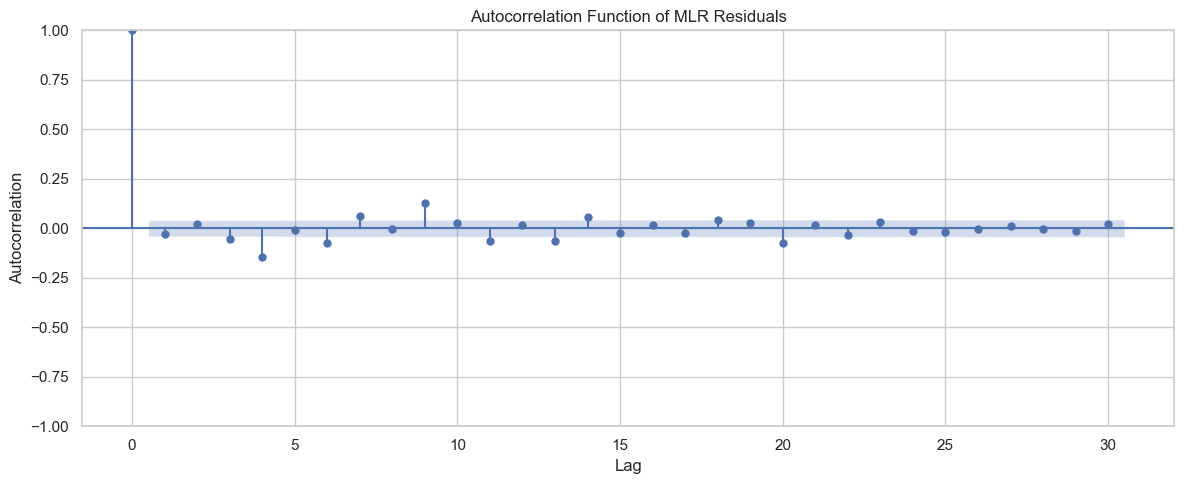

In [26]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    mlr_residuals,
    lags=30,
    alpha=0.05,
    ax=ax
)

ax.set_title('Autocorrelation Function of MLR Residuals')
ax.set_xlabel('Lag')
ax.set_ylabel('Autocorrelation')

plt.tight_layout()
plt.show()

### Interpretation of Residual Autocorrelation Function

The Autocorrelation Function (ACF) plot was examined to investigate the relationship between multiple linear regression residuals across different time lags.

The plot indicates that most autocorrelation coefficients are relatively small. However, several lags, particularly lags 4, 6, 9, 11, 13 and 20, appear to extend beyond the approximate confidence bands, indicating statistically significant autocorrelation at these individual lags.

The autocorrelation coefficients fluctuate between positive and negative values without displaying a clear pattern of gradual decay.

These observations are consistent with the Breusch-Godfrey test, which produced an LM statistic of 63.2310 and a p-value below 0.001, providing strong evidence of serial correlation across the first five lags.

Although the Durbin-Watson statistic of 2.058 initially suggested little first-order autocorrelation, the ACF plot and Breusch-Godfrey test reveal evidence of residual dependence across multiple lags.

Overall, the diagnostic results indicate that the residual independence assumption is not satisfied. Consequently, conventional OLS standard errors may be unreliable, and heteroscedasticity and autocorrelation consistent (HAC) standard errors will be considered during subsequent model evaluation.

## 12. Residual Normality Analysis

Residual normality is examined to determine whether the errors from the multiple linear regression model approximately follow a normal distribution.

The analysis employs a Normal Quantile-Quantile (Q-Q) plot and the Jarque-Bera statistical test.

The Q-Q plot provides a visual comparison between the observed residual distribution and a theoretical normal distribution, while the Jarque-Bera test evaluates departures from normality based on skewness and kurtosis.

This diagnostic is relevant to conventional statistical inference, particularly the validity of exact small-sample t-tests and F-tests.

### A. Normal Q-Q Plot

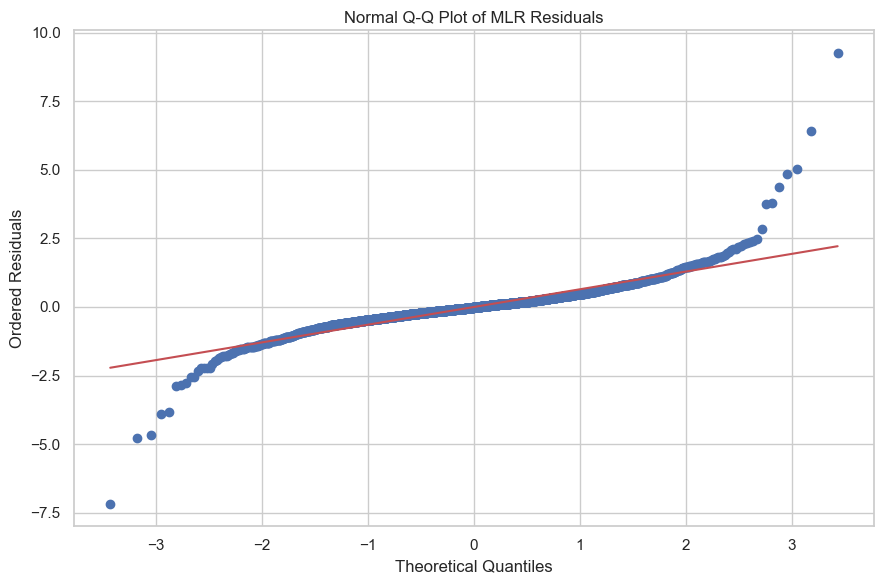

In [27]:
import scipy.stats as stats
fig, ax = plt.subplots(figsize=(9, 6))

stats.probplot(
    mlr_residuals,
    dist="norm",
    plot=ax
)

ax.set_title('Normal Q-Q Plot of MLR Residuals')
ax.set_xlabel('Theoretical Quantiles')
ax.set_ylabel('Ordered Residuals')

plt.tight_layout()
plt.show()

### B. Jarque-Bera Test

In [28]:
from scipy.stats import jarque_bera

jb_stat, jb_pvalue = jarque_bera(mlr_residuals)

print("Jarque-Bera Statistic:", jb_stat)
print("P-value:", jb_pvalue)

Jarque-Bera Statistic: 65527.23620388115
P-value: 0.0


In [29]:
residual_distribution = pd.DataFrame({
    'Metric': ['Skewness', 'Excess Kurtosis'],
    'Value': [
        mlr_residuals.skew(),
        mlr_residuals.kurt()
    ]
})

display(residual_distribution)

,Metric,Value
0,Skewness,0.9766
1,Excess Kurtosis,26.0213


### Interpretation of Residual Normality Analysis

Residual normality was examined using a Normal Quantile-Quantile (Q-Q) plot and the Jarque-Bera statistical test.

The Q-Q plot indicates that the central portion of the residual distribution follows the theoretical normal reference line reasonably closely. However, substantial deviations are visible in both tails, with particularly pronounced departures among extreme positive residuals. This suggests that the residual distribution exhibits heavier tails than a normal distribution.

The Jarque-Bera test produced a statistic of 65,527.2362 with a p-value below 0.001. Consequently, the null hypothesis of normally distributed residuals is rejected at the 5% significance level.

The residual distribution exhibits positive skewness of 0.9766 and excess kurtosis of 26.0213. These values indicate an asymmetric distribution with substantial tail behaviour and a pronounced presence of extreme observations.

Overall, the diagnostic results provide strong evidence that the MLR residuals are not normally distributed. This finding is consistent with the extreme market movements identified during exploratory data analysis.

Although residual normality is relevant to conventional small-sample statistical inference, its violation does not automatically invalidate OLS coefficient estimates. However, the finding must be considered when evaluating statistical inference, particularly alongside the previously identified residual autocorrelation.

## 13. Multicollinearity Analysis

Multicollinearity occurs when two or more explanatory variables in a regression model exhibit strong linear relationships with one another.

High multicollinearity can increase the variance of estimated regression coefficients, making individual coefficient estimates less precise and their statistical significance more difficult to establish.

The Variance Inflation Factor (VIF) is employed to assess the extent of multicollinearity among the explanatory variables in the multiple linear regression model.

In [30]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_data = pd.DataFrame()

vif_data['Variable'] = X_mlr.columns

vif_data['VIF'] = [
    variance_inflation_factor(X_mlr.values, i)
    for i in range(X_mlr.shape[1])
]

display(vif_data)

,Variable,VIF
0,const,1.0000
1,VIX_Change,1.0354
2,Treasury_10Y_Change,1.0401
3,Brent_Oil_Return,1.0478
4,Fed_Rate_Change,1.0047


### Interpretation of Variance Inflation Factors

The Variance Inflation Factor (VIF) was calculated to assess the extent of multicollinearity among the explanatory variables included in the multiple linear regression model.

The results indicate VIF values of 1.0354 for VIX changes, 1.0401 for Treasury yield changes, 1.0478 for Brent crude oil returns and 1.0047 for Federal Funds Rate changes.

All explanatory variables exhibit VIF values very close to 1, indicating very limited linear dependence among the predictors.

These results provide no evidence of problematic multicollinearity within the multiple regression model. Consequently, substantial inflation of coefficient variances due to linear relationships among the included explanatory variables is unlikely.

Overall, multicollinearity does not appear to be a significant concern for the estimated model. The individual coefficient estimates can therefore be evaluated without evidence of substantial variance inflation arising from relationships among the selected predictors.

## 14. Influential Observations Analysis

Influential observations analysis is conducted to identify individual observations that may disproportionately affect the estimated multiple linear regression model.

The analysis employs studentised residuals, leverage values and Cook's Distance to investigate unusual residual behaviour, extreme predictor combinations and the influence of individual observations on regression estimates.

Given the presence of extreme financial market movements and heavy-tailed residuals identified during earlier diagnostic analysis, evaluating influential observations is particularly important.

The identified observations will be investigated rather than automatically removed, as extreme financial movements may represent genuine market events.

In [31]:
from statsmodels.stats.outliers_influence import OLSInfluence
# Calculate influence statistics
influence = OLSInfluence(mlr_model)

# Extract diagnostic measures
studentized_residuals = influence.resid_studentized_external
leverage_values = influence.hat_matrix_diag
cooks_distance = influence.cooks_distance[0]

# Create diagnostic dataframe
influence_data = pd.DataFrame({
    'Date': df['Date'].values,
    'Studentized_Residual': studentized_residuals,
    'Leverage': leverage_values,
    'Cooks_Distance': cooks_distance
})

display(influence_data.head())

,Date,Studentized_Residual,Leverage,Cooks_Distance
0,2016-11-04,0.0284,0.0007,0.0000
1,2016-11-07,0.6645,0.0022,0.0002
2,2016-11-08,0.4217,0.0008,0.0000
3,2016-11-09,-1.3659,0.0073,0.0027
4,2016-11-10,0.4201,0.0015,0.0001


In [32]:
n = len(df)
k = 4

# Diagnostic thresholds
leverage_threshold = 2 * (k + 1) / n
cooks_threshold = 4 / n

# Identify unusual observations
influential_observations = influence_data[
    (abs(influence_data['Studentized_Residual']) > 3) |
    (influence_data['Leverage'] > leverage_threshold) |
    (influence_data['Cooks_Distance'] > cooks_threshold)
]

print("Leverage Threshold:", leverage_threshold)
print("Cook's Distance Threshold:", cooks_threshold)

print(
    "Number of potentially influential observations:",
    len(influential_observations)
)

display(influential_observations.sort_values(
    'Cooks_Distance',
    ascending=False
).head(15))

Leverage Threshold: 0.004310344827586207
Cook's Distance Threshold: 0.0017241379310344827
Number of potentially influential observations: 193


,Date,Studentized_Residual,Leverage,Cooks_Distance
294,2018-02-05,7.0669,0.0451,0.4625
794,2020-03-20,-10.4483,0.0143,0.3022
792,2020-03-18,-6.7100,0.0218,0.1965
1806,2024-08-05,5.4568,0.0259,0.1561
790,2020-03-16,-1.7182,0.1898,0.1382
992,2021-01-27,5.4015,0.0229,0.1349
1408,2022-11-10,6.3115,0.0163,0.1299
804,2020-04-03,-5.4783,0.0186,0.1122
813,2020-04-21,-2.1251,0.0964,0.0962
1807,2024-08-06,-5.5759,0.0152,0.0946


### Interpretation of Influential Observations Analysis

Influential observations were investigated using externally studentised residuals, leverage values and Cook's Distance.

The analysis identified 193 potentially influential observations out of 2,320 observations, based on whether at least one of the diagnostic screening thresholds was exceeded.

The observation dated 5 February 2018 exhibited the highest Cook's Distance of 0.4625, accompanied by a studentised residual of 7.0669 and a leverage value of 0.0451. This indicates that the observation combines an unusually large residual with relatively high leverage, resulting in substantial influence on the estimated regression model.

Several observations from March and April 2020 also exhibited relatively high Cook's Distance values. In particular, observations dated 18 March and 20 March 2020 produced Cook's Distance values of 0.1965 and 0.3022, respectively. The observation dated 24 March 2020 exhibited an exceptionally large studentised residual of 13.6206.

Additional potentially influential observations were identified during 2021, 2022 and 2024. These findings indicate that certain periods within the sample may have a disproportionate influence on the estimated regression coefficients.

An important observation is that high leverage does not necessarily coincide with an unusually large residual. For example, the observation dated 16 March 2020 exhibited a leverage value of 0.1898 despite having a studentised residual of -1.7182. Its Cook's Distance of 0.1382 nevertheless indicates considerable influence.

Overall, the analysis identifies several observations that warrant further investigation. However, these observations will not be automatically removed because extreme financial market movements may represent genuine market behaviour rather than data errors. Their potential influence will instead be considered through subsequent model evaluation and sensitivity analysis.

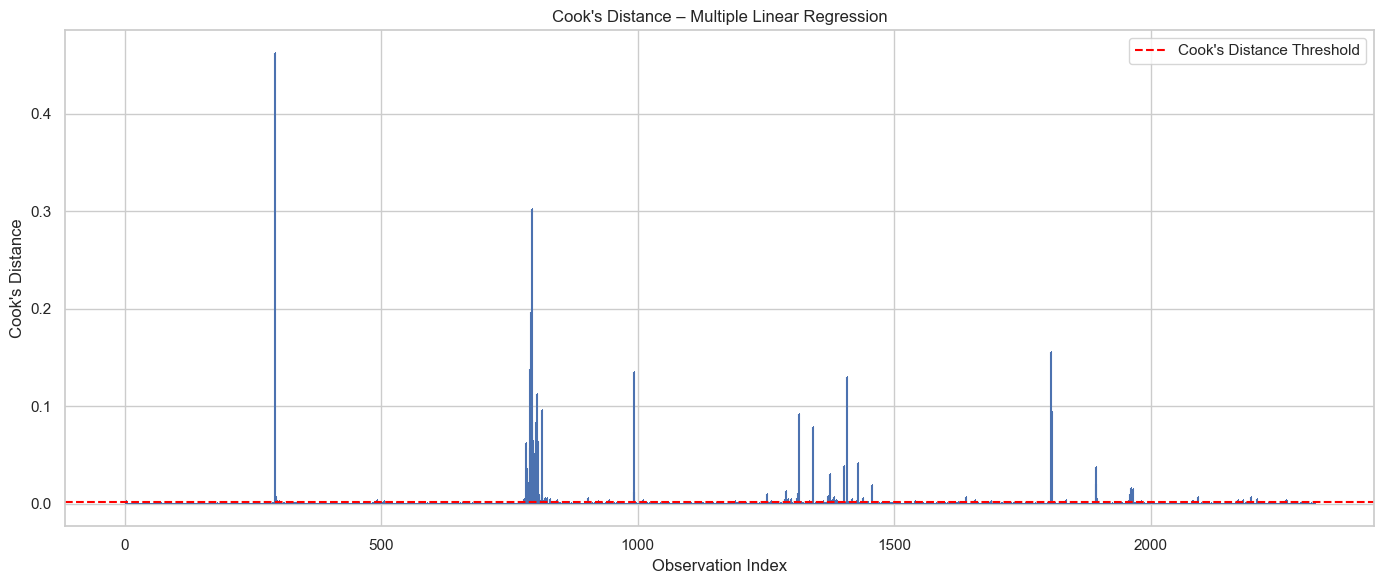

In [33]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.stem(
    np.arange(len(cooks_distance)),
    cooks_distance,
    markerfmt=',',
    basefmt=' '
)

ax.axhline(
    cooks_threshold,
    linestyle='--',
    color='red',
    label="Cook's Distance Threshold"
)

ax.set_title("Cook's Distance – Multiple Linear Regression")
ax.set_xlabel("Observation Index")
ax.set_ylabel("Cook's Distance")
ax.legend()

plt.tight_layout()
plt.show()

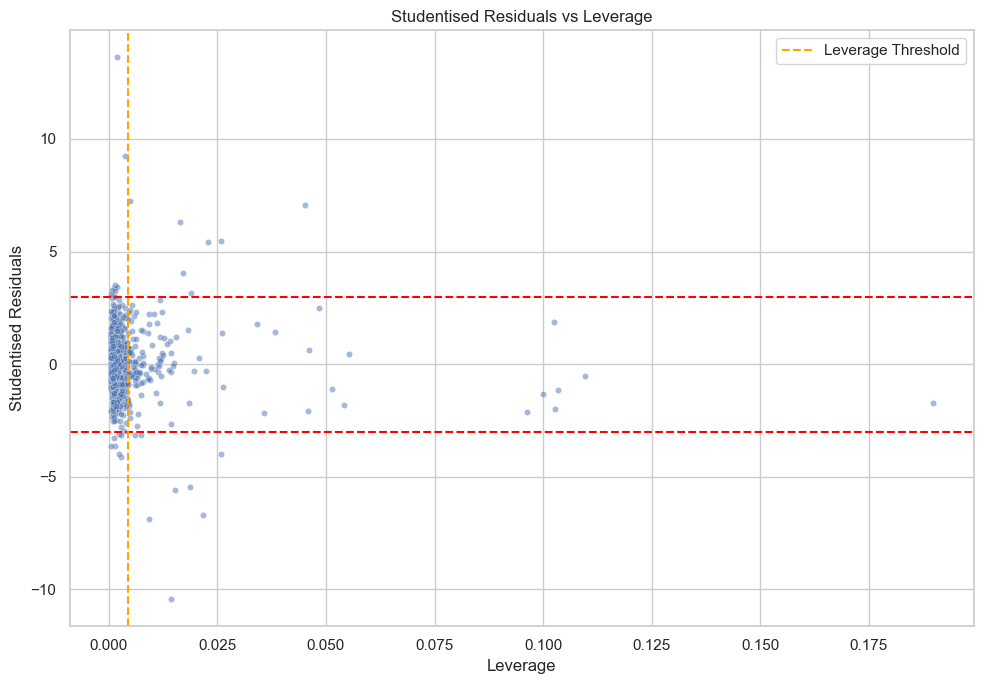

In [34]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=leverage_values,
    y=studentized_residuals,
    alpha=0.5,
    s=20
)

plt.axhline(3, linestyle='--', color='red')
plt.axhline(-3, linestyle='--', color='red')

plt.axvline(
    leverage_threshold,
    linestyle='--',
    color='orange',
    label='Leverage Threshold'
)

plt.title('Studentised Residuals vs Leverage')
plt.xlabel('Leverage')
plt.ylabel('Studentised Residuals')
plt.legend()

plt.tight_layout()
plt.show()

### Interpretation of Influential Observations Visualisations

The Cook's Distance plot indicates that the influence of individual observations is concentrated in specific periods rather than being uniformly distributed throughout the sample.

A particularly prominent spike is visible around observation 294, corresponding to 5 February 2018. Additional clusters of elevated Cook's Distance values appear around observations 790–813, corresponding to March–April 2020, as well as other periods later in the sample.

Most observations exhibit relatively low Cook's Distance values, although several substantially exceed the screening threshold of 4/n. This indicates that certain observations have a comparatively greater influence on the estimated regression coefficients.

The studentised residuals versus leverage plot further identifies observations with unusually large residuals and unusual combinations of explanatory-variable values. Several observations exceed the absolute studentised residual threshold of 3, while others exceed the calculated leverage threshold of approximately 0.00431.

A number of observations exhibit both elevated residual magnitudes and relatively high leverage, indicating potentially substantial influence on the regression estimates.

Overall, the visual diagnostics reinforce the numerical findings from the influential observations analysis. The model appears sensitive to certain extreme financial market observations, particularly during periods of elevated market activity. These observations will be retained because they may represent genuine market movements rather than data errors. Their influence will be considered through subsequent model evaluation and sensitivity analysis.

## 15. HC3 Robust Standard Errors

Following the regression diagnostic analysis, HC3 heteroscedasticity-consistent standard errors are employed to evaluate the robustness of the multiple linear regression results.

Although the Breusch-Pagan test did not identify statistically significant heteroscedasticity, the presence of influential observations and departures from the classical regression assumptions motivates the use of robust covariance estimation as an additional sensitivity analysis.

The HC3 covariance estimator adjusts the estimated standard errors to provide inference that is robust to heteroscedasticity, with additional consideration for observations exhibiting high leverage.

The regression coefficients remain unchanged. However, standard errors, t-statistics, p-values and confidence intervals may differ from those obtained using conventional OLS estimation.

Since HC3 does not account for serial correlation, Newey-West HAC standard errors will be examined separately.

In [35]:
# Calculate HC3 robust standard errors
mlr_hc3 = mlr_model.get_robustcov_results(cov_type='HC3')

# Display regression results
print(mlr_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:           SP500_Return   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     160.1
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          4.53e-121
Time:                        02:10:12   Log-Likelihood:                -2486.9
No. Observations:                2320   AIC:                             4984.
Df Residuals:                    2315   BIC:                             5013.
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.0497    

In [36]:
# Extract conventional and HC3 results

comparison_hc3 = pd.DataFrame({
    'Variable': mlr_model.params.index,

    'OLS_Coefficient': mlr_model.params.values,
    'OLS_Std_Error': mlr_model.bse.values,
    'OLS_P_Value': mlr_model.pvalues.values,

    'HC3_Coefficient': mlr_hc3.params,
    'HC3_Std_Error': mlr_hc3.bse,
    'HC3_P_Value': mlr_hc3.pvalues
})

display(comparison_hc3.round(5))

,Variable,OLS_Coefficient,OLS_Std_Error,OLS_P_Value,HC3_Coefficient,HC3_Std_Error,HC3_P_Value
0,const,0.0497,0.0147,0.0007,0.0497,0.0149,0.0009
1,VIX_Change,-0.4484,0.0075,0.0000,-0.4484,0.0192,0.0000
2,Treasury_10Y_Change,0.2438,0.2806,0.3851,0.2438,0.5231,0.6412
3,Brent_Oil_Return,0.0204,0.0047,0.0000,0.0204,0.0094,0.0295
4,Fed_Rate_Change,-0.6229,0.2982,0.0368,-0.6229,0.4755,0.1903


### Interpretation of HC3 Robust Standard Errors

HC3 heteroscedasticity-consistent standard errors were calculated to evaluate the robustness of the multiple linear regression results.

The regression coefficients remain unchanged, as HC3 adjusts the estimated covariance matrix rather than the underlying OLS coefficient estimates. However, the standard errors increased across all four explanatory variables, resulting in changes to their corresponding t-statistics and p-values.

VIX changes remain highly statistically significant, with a coefficient of -0.4484 and an HC3-adjusted p-value below 0.001. This indicates that the negative relationship between VIX changes and S&P 500 returns remains statistically significant under HC3 inference.

Brent crude oil returns also remain statistically significant at the 5% level, with a coefficient of 0.0204 and an adjusted p-value of 0.0295. However, the evidence is weaker than under conventional OLS inference.

Treasury yield changes remain statistically insignificant, with an adjusted p-value of 0.6412.

An important change concerns Federal Funds Rate changes. Although this variable was statistically significant under conventional OLS inference (p = 0.0368), its HC3-adjusted p-value increases to 0.1903. Consequently, it is no longer statistically significant at the 5% level.

The overall model remains statistically significant, with an HC3-adjusted F-statistic of 160.1 and a corresponding p-value of approximately 4.53 × 10⁻¹²¹. The R-squared remains unchanged at 0.6228.

Overall, the HC3 results indicate that the statistical significance of the Federal Funds Rate variable is sensitive to the covariance estimator, whereas the relationships involving VIX changes and Brent crude oil returns remain statistically significant.

It is important to note that HC3 addresses heteroscedasticity but does not account for serial correlation. Since the Breusch-Godfrey test identified significant residual autocorrelation, Newey-West HAC standard errors will be examined next to evaluate the robustness of statistical inference to both heter

### 16. Newey-West HAC Standard Errors

Newey-West heteroscedasticity and autocorrelation consistent (HAC) standard errors are employed to address the residual serial correlation identified during regression diagnostics.

The Breusch-Godfrey test provided strong evidence of autocorrelation up to the fifth lag. Consequently, conventional OLS and HC3 standard errors may not adequately account for the temporal dependence present in the regression residuals.

The Newey-West covariance estimator adjusts the estimated coefficient covariance matrix to account for both heteroscedasticity and autocorrelation up to a specified lag.

The underlying OLS coefficient estimates remain unchanged, while the estimated standard errors, test statistics, p-values and confidence intervals may differ.

This analysis will help determine whether the relationships identified in the multiple linear regression model remain statistically significant after accounting for serial dependence.

In [37]:
# Calculate Newey-West HAC robust standard errors
mlr_hac = mlr_model.get_robustcov_results(
    cov_type='HAC',
    maxlags=5
)

# Display regression results
print(mlr_hac.summary())

                            OLS Regression Results                            
Dep. Variable:           SP500_Return   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     123.0
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           2.52e-95
Time:                        02:10:12   Log-Likelihood:                -2486.9
No. Observations:                2320   AIC:                             4984.
Df Residuals:                    2315   BIC:                             5013.
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.0497    

In [38]:
comparison_robust = pd.DataFrame({
    'Variable': mlr_model.params.index,

    'OLS_Std_Error': mlr_model.bse.values,
    'OLS_P_Value': mlr_model.pvalues.values,

    'HC3_Std_Error': mlr_hc3.bse,
    'HC3_P_Value': mlr_hc3.pvalues,

    'HAC_Std_Error': mlr_hac.bse,
    'HAC_P_Value': mlr_hac.pvalues
})

display(comparison_robust.round(5))

,Variable,OLS_Std_Error,OLS_P_Value,HC3_Std_Error,HC3_P_Value,HAC_Std_Error,HAC_P_Value
0,const,0.0147,0.0007,0.0149,0.0009,0.0135,0.0002
1,VIX_Change,0.0075,0.0000,0.0192,0.0000,0.0220,0.0000
2,Treasury_10Y_Change,0.2806,0.3851,0.5231,0.6412,0.6058,0.6874
3,Brent_Oil_Return,0.0047,0.0000,0.0094,0.0295,0.0081,0.0121
4,Fed_Rate_Change,0.2982,0.0368,0.4755,0.1903,0.4351,0.1524


### Interpretation of Newey-West HAC Standard Errors

Newey-West heteroscedasticity and autocorrelation consistent (HAC) standard errors were calculated using five lags to account for the serial correlation identified during regression diagnostics.

The regression coefficients and R-squared remain unchanged, as the HAC estimator adjusts the estimated covariance matrix rather than the underlying OLS model. However, the standard errors, test statistics and p-values differ from those obtained using conventional OLS and HC3 covariance estimators.

VIX changes remain highly statistically significant, with a coefficient of -0.4484 and a HAC-adjusted p-value below 0.001. This indicates that the negative relationship between VIX changes and S&P 500 returns remains statistically significant after accounting for heteroscedasticity and autocorrelation.

Brent crude oil returns also remain statistically significant at the 5% level, with a coefficient of 0.0204 and an adjusted p-value of 0.0121. Although the evidence is weaker than under conventional OLS inference, the relationship remains statistically significant under HAC estimation.

Treasury yield changes remain statistically insignificant, with an adjusted p-value of 0.6874. Federal Funds Rate changes also remain statistically insignificant, with an adjusted p-value of 0.1524.

The overall regression model remains statistically significant, producing a HAC-adjusted F-statistic of 123.0 and a corresponding p-value of approximately 2.52 × 10⁻⁹⁵. The R-squared remains 0.6228.

Overall, the HAC results reinforce the robustness of the relationships involving VIX changes and Brent crude oil returns. In contrast, the results provide insufficient evidence of independent linear relationships involving Treasury yield changes and Federal Funds Rate changes.

These findings suggest that the statistical significance of VIX and Brent oil is relatively robust to the covariance estimation methods examined, whereas the initial significance of Federal Funds Rate changes under conventional OLS inference is not robust.

The HAC estimator improves statistical inference in the presence of heteroscedasticity and serial correlation but does not eliminate residual autocorrelation or address potential model misspecification.

In [39]:
hac_lags = [1, 5, 10, 20]

hac_sensitivity = {}

for lag in hac_lags:
    hac_model = mlr_model.get_robustcov_results(
        cov_type='HAC',
        maxlags=lag
    )

    hac_sensitivity[lag] = {
        'Std_Error': hac_model.bse,
        'P_Value': hac_model.pvalues
    }

hac_sensitivity_table = pd.DataFrame({
    'Variable': mlr_model.params.index
})

for lag in hac_lags:
    hac_sensitivity_table[f'SE_Lag_{lag}'] = (
        hac_sensitivity[lag]['Std_Error']
    )

    hac_sensitivity_table[f'P_Value_Lag_{lag}'] = (
        hac_sensitivity[lag]['P_Value']
    )

display(hac_sensitivity_table.round(5))

,Variable,SE_Lag_1,P_Value_Lag_1,SE_Lag_5,P_Value_Lag_5,SE_Lag_10,P_Value_Lag_10,SE_Lag_20,P_Value_Lag_20
0,const,0.0146,0.0006,0.0135,0.0002,0.0128,0.0001,0.0127,0.0001
1,VIX_Change,0.0208,0.0000,0.0220,0.0000,0.0222,0.0000,0.0220,0.0000
2,Treasury_10Y_Change,0.5533,0.6596,0.6058,0.6874,0.6626,0.7130,0.7544,0.7466
3,Brent_Oil_Return,0.0094,0.0296,0.0081,0.0121,0.0078,0.0094,0.0069,0.0029
4,Fed_Rate_Change,0.4322,0.1496,0.4351,0.1524,0.4138,0.1324,0.3907,0.1110


### Interpretation of HAC Lag Sensitivity Analysis

A HAC lag sensitivity analysis was conducted using alternative lag specifications of 1, 5, 10 and 20 to investigate whether the statistical significance of the multiple regression coefficients depends substantially on the selected bandwidth.

VIX changes remain highly statistically significant across all four specifications, with p-values below 0.001. This indicates that the negative relationship between VIX changes and S&P 500 returns is robust to the alternative HAC lag choices examined.

Treasury yield changes remain statistically insignificant across all specifications, with p-values ranging from 0.6596 to 0.7466. Federal Funds Rate changes also remain statistically insignificant, with p-values ranging from 0.1110 to 0.1524.

Brent crude oil returns remain statistically significant at the 5% level across all four specifications. However, the estimated standard errors and p-values vary with the selected lag length, indicating some sensitivity in the estimated precision of this coefficient.

Overall, the sensitivity analysis demonstrates that the principal statistical conclusions remain consistent across the HAC lag specifications examined. VIX changes and Brent crude oil returns retain statistically significant relationships with S&P 500 returns, whereas Treasury yield changes and Federal Funds Rate changes remain statistically insignificant.

The five-lag HAC specification is retained as the primary inference model, while the alternative lag specifications provide supporting sensitivity evidence.

In [40]:
# Identify observations below the Cook's Distance threshold

sensitivity_mask = cooks_distance <= cooks_threshold

# Create sensitivity dataset
df_sensitivity = df.loc[sensitivity_mask].copy()

print("Original observations:", len(df))
print("Sensitivity observations:", len(df_sensitivity))
print("Observations excluded:", (~sensitivity_mask).sum())

# Define independent and dependent variables

X_sensitivity = df_sensitivity[
    [
        'VIX_Change',
        'Treasury_10Y_Change',
        'Brent_Oil_Return',
        'Fed_Rate_Change'
    ]
]

y_sensitivity = df_sensitivity['SP500_Return']

# Add intercept
X_sensitivity = sm.add_constant(X_sensitivity)

# Estimate regression
mlr_sensitivity = sm.OLS(
    y_sensitivity,
    X_sensitivity
).fit()

print(mlr_sensitivity.summary())


Original observations: 2320
Sensitivity observations: 2205
Observations excluded: 115
                            OLS Regression Results                            
Dep. Variable:           SP500_Return   R-squared:                       0.670
Model:                            OLS   Adj. R-squared:                  0.669
Method:                 Least Squares   F-statistic:                     1117.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:10:12   Log-Likelihood:                -1571.2
No. Observations:                2205   AIC:                             3152.
Df Residuals:                    2200   BIC:                             3181.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------

In [41]:
coefficient_comparison = pd.DataFrame({
    'Variable': mlr_model.params.index,

    'Original_Coefficient': mlr_model.params.values,

    'Sensitivity_Coefficient': mlr_sensitivity.params.values
})

coefficient_comparison['Coefficient_Change'] = (
    coefficient_comparison['Sensitivity_Coefficient']
    - coefficient_comparison['Original_Coefficient']
)

display(coefficient_comparison.round(5))

,Variable,Original_Coefficient,Sensitivity_Coefficient,Coefficient_Change
0,const,0.0497,0.0406,-0.0091
1,VIX_Change,-0.4484,-0.4911,-0.0427
2,Treasury_10Y_Change,0.2438,-0.0374,-0.2812
3,Brent_Oil_Return,0.0204,0.0140,-0.0064
4,Fed_Rate_Change,-0.6229,-0.1322,0.4907


### Interpretation

A sensitivity analysis was conducted by excluding observations with Cook's Distance values exceeding the threshold of 4/n. This resulted in the removal of 115 observations, reducing the sample size from 2,320 to 2,205.

Following the exclusion, the model's R-squared increased from approximately 0.623 to 0.670. However, this increase should be interpreted cautiously because the models were estimated using different samples.

The coefficient comparison revealed varying degrees of sensitivity across the explanatory variables. The negative coefficient associated with VIX changes became stronger, while the positive relationship between Brent Oil returns and S&P 500 returns remained statistically significant, although its magnitude decreased.

In contrast, the Treasury 10-year yield coefficient changed direction and remained statistically insignificant. The Federal Funds Rate coefficient also decreased substantially in magnitude and became statistically insignificant. These changes indicate that the estimated relationships involving Treasury yield changes and Federal Funds Rate changes are particularly sensitive to influential observations.

The residual distribution also showed reduced skewness and kurtosis compared with the original model, although the Jarque-Bera test continued to reject the normality assumption.

Overall, the sensitivity analysis suggests that the negative relationship between VIX changes and S&P 500 returns, as well as the positive relationship involving Brent Oil returns, are relatively stable. The estimated effects of Treasury yield changes and Federal Funds Rate changes are less robust to the exclusion of influential observations.

Importantly, the excluded observations may represent genuine periods of significant financial market activity rather than data errors. Therefore, the reduced-sample model is treated as a sensitivity check rather than a replacement for the original model. The full-sample model remains the primary specification to preserve observations representing extreme market conditions.

### 17. Breusch-Godfrey Test

The Breusch-Godfrey test was repeated on the sensitivity model to examine whether excluding influential observations affected the presence of residual autocorrelation.

The test produced an LM statistic of 2.686 with a p-value of 0.7483. The corresponding F-statistic was 0.535, with a p-value of 0.7497.

Since both p-values exceed the 0.05 significance level, the null hypothesis of no residual autocorrelation up to lag 5 cannot be rejected.

This contrasts with the original MLR model, which exhibited statistically significant residual autocorrelation. The result suggests that excluding observations identified through Cook's Distance materially changes the serial dependence observed in the residuals.

Nevertheless, this finding should be interpreted cautiously. The reduction in autocorrelation does not establish that the excluded observations were erroneous or that their removal produces a more representative model. The original observations may capture genuine periods of market stress and unusual financial activity.

Consequently, the full-sample model remains the primary specification, while the reduced-sample model provides evidence that the regression diagnostics and coefficient estimates are sensitive to influential observations.

In [42]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

bg_sensitivity = acorr_breusch_godfrey(
    mlr_sensitivity,
    nlags=5
)

print("LM Statistic:", bg_sensitivity[0])
print("LM p-value:", bg_sensitivity[1])
print("F Statistic:", bg_sensitivity[2])
print("F p-value:", bg_sensitivity[3])

LM Statistic: 2.685505365638636
LM p-value: 0.7483344192554432
F Statistic: 0.5353172121364471
F p-value: 0.7496670524940474


C:\Users\reshma begum\AppData\Local\Temp\ipykernel_16652\231265944.py:3: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_sensitivity = acorr_breusch_godfrey(


### 18. Statistical Inference

In [43]:
# Extract Newey-West HAC coefficient results

hac_results = pd.DataFrame({
    'Coefficient': mlr_hac.params,
    'Std_Error': mlr_hac.bse,
    't_Statistic': mlr_hac.tvalues,
    'p_Value': mlr_hac.pvalues
})

# Add confidence intervals
hac_ci = mlr_hac.conf_int()

hac_results['CI_Lower'] = hac_ci[:, 0]
hac_results['CI_Upper'] = hac_ci[:, 1]

# Determine statistical significance
hac_results['Significant'] = (
    hac_results['p_Value'] < 0.05
)

display(hac_results.round(5))

,Coefficient,Std_Error,t_Statistic,p_Value,CI_Lower,CI_Upper,Significant
0,0.0497,0.0135,3.6778,0.0002,0.0232,0.0762,True
1,-0.4484,0.0220,-20.3702,0.0000,-0.4916,-0.4053,True
2,0.2438,0.6058,0.4024,0.6874,-0.9441,1.4316,False
3,0.0204,0.0081,2.5096,0.0121,0.0045,0.0363,True
4,-0.6229,0.4351,-1.4316,0.1524,-1.4761,0.2303,False


### Interpretation

Individual hypothesis tests were conducted using Newey-West HAC standard errors with five lags, at a 5% significance level.

The results indicate that VIX changes and Brent Oil returns are statistically significant explanatory variables. VIX changes exhibit a negative coefficient of -0.4484 (p < 0.001), indicating that increases in market volatility are associated with lower S&P 500 returns, holding the other variables constant. Brent Oil returns exhibit a positive coefficient of 0.0204 (p = 0.0121), indicating a statistically significant positive association with S&P 500 returns.

In contrast, Treasury 10-year yield changes (p = 0.6874) and Federal Funds Rate changes (p = 0.1524) are not statistically significant at the 5% level. Their respective confidence intervals include zero, suggesting insufficient evidence of independent linear associations within the specified model.

The findings indicate that VIX changes provide the strongest statistical association with S&P 500 returns among the four explanatory variables. Brent Oil returns also demonstrate a statistically significant relationship, although its estimated coefficient is considerably smaller.

Overall, the individual hypothesis tests identify VIX changes and Brent Oil returns as statistically significant variables under HAC-robust inference. These results describe conditional statistical associations and should not be interpreted as evidence of causation.

In [44]:
# Joint hypothesis test using HAC covariance matrix

joint_test = mlr_hac.f_test(
    "VIX_Change = 0, Treasury_10Y_Change = 0, "
    "Brent_Oil_Return = 0, Fed_Rate_Change = 0"
)

print(joint_test)

<F test: F=123.04859645013224, p=2.5228630044588042e-95, df_denom=2.32e+03, df_num=4>


### Overall Model Significance

A joint Wald test was conducted using the Newey-West HAC covariance matrix to evaluate whether the explanatory variables were jointly significant in explaining S&P 500 returns.

The null hypothesis stated that all four explanatory variable coefficients were simultaneously equal to zero, while the alternative hypothesis stated that at least one coefficient was different from zero.

The test produced an F-statistic of 123.0486 and a p-value of approximately 2.52 × 10⁻⁹⁵.

Since the p-value is considerably below the 5% significance level, the null hypothesis is rejected. This provides strong statistical evidence that the explanatory variables are jointly associated with S&P 500 returns.

Although the joint test confirms the overall statistical significance of the model, the individual hypothesis tests indicate that VIX changes and Brent Oil returns are the variables that retain statistical significance under HAC-robust inference. Treasury 10-year yield changes and Federal Funds Rate changes are not individually significant.

Overall, the joint Wald test supports the statistical relevance of the MLR specification, while the individual tests identify which explanatory variables contribute statistically significant associations.

In [45]:
# Compare Simple and Multiple Linear Regression models

model_comparison = pd.DataFrame({
    'Metric': [
        'R-squared',
        'Adjusted R-squared',
        'AIC',
        'BIC',
        'Observations'
    ],
    'SLR': [
        slr_model.rsquared,
        slr_model.rsquared_adj,
        slr_model.aic,
        slr_model.bic,
        int(slr_model.nobs)
    ],
    'MLR': [
        mlr_model.rsquared,
        mlr_model.rsquared_adj,
        mlr_model.aic,
        mlr_model.bic,
        int(mlr_model.nobs)
    ]
})

display(model_comparison.round(4))

,Metric,SLR,MLR
0,R-squared,0.6187,0.6228
1,Adjusted R-squared,0.6185,0.6221
2,AIC,5002.8226,4983.8121
3,BIC,5014.3212,5012.5587
4,Observations,2320.0000,2320.0000


### Interpretation

The Simple Linear Regression (SLR) and Multiple Linear Regression (MLR) models were compared to evaluate whether incorporating additional financial market indicators improves the explanatory performance of the regression model.

The SLR model, which uses only VIX changes as an explanatory variable, achieved an R-squared of 0.6187 and an adjusted R-squared of 0.6185. The MLR model achieved an R-squared of 0.6228 and an adjusted R-squared of 0.6221.

The addition of Treasury 10-year yield changes, Brent Oil returns and Federal Funds Rate changes increased the R-squared by approximately 0.41 percentage points. Although this represents an improvement, the relatively small increase indicates that VIX changes account for most of the explanatory power captured by the regression models.

The MLR model also produced lower AIC and BIC values than the SLR model. Since both models were estimated using the same dependent variable and observations, these results provide additional support for the MLR specification, although the BIC improvement was comparatively modest.

Overall, incorporating additional financial indicators provides a modest improvement in explanatory performance. However, VIX changes remain the dominant explanatory variable, while Brent Oil returns provide an additional statistically significant association under HAC-robust inference.

The comparison is based on in-sample explanatory performance and does not establish that the MLR model will produce more accurate forecasts. Out-of-sample forecasting performance will be examined separately in the time-series analysis.

### Summary of Statistical Inference

The regression analysis examined the relationship between S&P 500 daily returns and four financial market indicators: VIX changes, Treasury 10-year yield changes, Brent Oil returns and Federal Funds Rate changes.

The Simple Linear Regression model demonstrated that VIX changes alone explained approximately 61.87% of the variation in S&P 500 returns. Incorporating the additional financial indicators through Multiple Linear Regression increased the explanatory power to approximately 62.28%.

Individual hypothesis tests using Newey-West HAC standard errors identified VIX changes and Brent Oil returns as statistically significant explanatory variables at the 5% significance level. VIX changes exhibited a negative association with S&P 500 returns, while Brent Oil returns exhibited a positive association. Treasury yield changes and Federal Funds Rate changes were not individually significant.

The joint HAC Wald test confirmed that the explanatory variables were jointly statistically significant (F = 123.05, p < 0.001). This indicates that the predictors collectively provide statistically significant explanatory information, despite some variables being individually insignificant.

The regression diagnostics identified significant residual autocorrelation and substantial deviations from normality in the original model. HC3 and Newey-West HAC standard errors were therefore examined to improve the reliability of statistical inference. The sensitivity analysis further demonstrated that coefficient estimates and residual diagnostics were affected by influential observations. Nevertheless, the full-sample model was retained as the primary specification to preserve genuine extreme market observations.

Overall, the findings suggest that VIX changes provide the strongest statistical association with daily S&P 500 returns, while Brent Oil returns contribute additional explanatory information. However, the relatively modest improvement from the MLR model indicates that incorporating additional contemporaneous financial indicators does not substantially increase the explanatory power beyond VIX alone.

These findings are based on contemporaneous relationships and do not establish causality or future forecasting ability. The next phase will investigate the time-series properties of S&P 500 returns and evaluate forecasting performance using chronological training and testing data.

## ADDITIONAL ANALYSIS White and ARCH-LM tests

In [46]:
# =====================================================================
# ADDITIONAL ANALYSIS White and ARCH-LM tests
# Notebook: PHASE 2 | New final section | Requires mlr_model, X_mlr
# =====================================================================
import pandas as pd
from statsmodels.stats.diagnostic import het_white, het_arch

resid = mlr_model.resid

w_lm, w_lm_p, w_f, w_f_p = het_white(resid, X_mlr)
white_table = pd.DataFrame({'Test': ['White (squares + cross-products)'],
                            'LM statistic': [w_lm], 'LM p-value': [w_lm_p],
                            'F statistic': [w_f], 'F p-value': [w_f_p]})
display(white_table)

arch_rows = []
for L in [1, 5, 10, 20]:
    lm, lm_p, f, f_p = het_arch(resid, nlags=L)
    arch_rows.append({'Lags': L, 'LM statistic': lm, 'LM p-value': lm_p,
                      'F statistic': f, 'F p-value': f_p})
display(pd.DataFrame(arch_rows))

,Test,LM statistic,LM p-value,F statistic,F p-value
0,White (squares + cross-products),228.7519,0.0000,18.0095,0.0000


C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,Lags,LM statistic,LM p-value,F statistic,F p-value
0,1,236.5717,0.0000,263.2200,0.0000
1,5,687.4328,0.0000,195.0497,0.0000
2,10,783.4305,0.0000,117.9839,0.0000
3,20,815.3916,0.0000,62.5848,0.0000
